# Implement linear regression model, apply regularization methods (Ridge and Lasso).
**Dataset:** `Salary_Data.csv` (30 rows): `YearsExperience` → `Salary`


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso, RidgeCV, LassoCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings("ignore")

## 1. Load and explore the data

In [9]:
df = pd.read_csv("D:\BDA 20\BDA LAB\AIML-BDA-Lab-Work\AssignmentFiles\data\Salary_Data.csv")
print(df.shape)
print(df.isnull().sum())
df.describe()


X = df[["YearsExperience"]]
y = df["Salary"]

(30, 2)
YearsExperience    0
Salary             0
dtype: int64


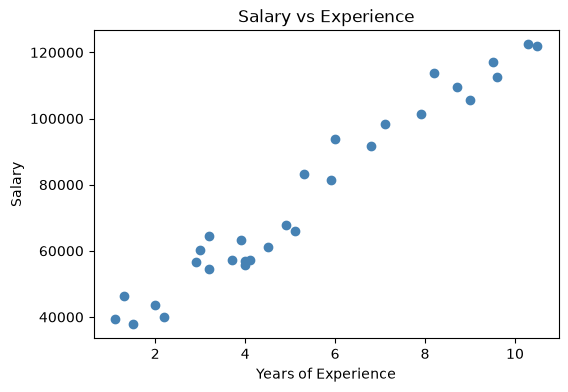

Correlation: 0.9782


In [10]:
plt.figure(figsize=(6, 4))
plt.scatter(df["YearsExperience"], df["Salary"], color="steelblue")
plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.title("Salary vs Experience")
plt.show()

print("Correlation:", round(df["YearsExperience"].corr(df["Salary"]), 4))

## 2. Train/test split

In [11]:
# Train/test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Models: Linear Regression, Ridge, Lasso (scaling is done inside a pipeline)
models = {
    "Linear Regression": LinearRegression(),
    "Ridge (alpha=1)": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    "Lasso (alpha=1)": make_pipeline(StandardScaler(), Lasso(alpha=1.0)),
}

# Fit and evaluate
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    print(f"{name}")
    print("  MAE :", round(mean_absolute_error(y_test, pred), 2))
    print("  RMSE:", round(np.sqrt(mean_squared_error(y_test, pred)), 2))
    print("  R2  :", round(r2_score(y_test, pred), 4))

Linear Regression
  MAE : 6286.45
  RMSE: 7059.04
  R2  : 0.9024
Ridge (alpha=1)
  MAE : 6192.22
  RMSE: 7191.02
  R2  : 0.8988
Lasso (alpha=1)
  MAE : 6286.37
  RMSE: 7059.11
  R2  : 0.9024
